In [ ]:
# Might need to use 'pip install torch torchvision scikit-learn' before running
import hashlib, json, os, re, random, time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image, ImageOps
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split

SEED = 42 # Sets a fixed seed
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# Defines global hyperparameters
IMG_SIZE = 64 # every image is resized to 64 x 64
BATCH_SIZE = 128
VAL_FRACTION = 0.2
TRAIN_LIMIT = None # None = all training images
CACHE_DIR = Path("cache"); CACHE_DIR.mkdir(exist_ok=True)

In [ ]:
# Redo of old code
CANDIDATES = [Path("ENEL707-Kaggle-Comp/Datasets"), Path("Datasets"), Path("data"), Path(".")]

def locate_data():
    for c in CANDIDATES:
        for pattern in ("train_labels.csv", "*/train_labels.csv"):
            hits = sorted(c.glob(pattern))
            if hits:
                return hits[0].parent
    raise FileNotFoundError(f"train_labels.csv not found. Notebook folder: {Path.cwd()}")

IMG_EXT = {".jpg"}

def id_key(text):
    m = re.match(r"\s*(\d+)", str(text))
    if m is None:
        raise ValueError(f"Expected an id starting with digits, got {text!r}")
    return int(m.group(1))

def index_folder(folder):
    index = {}
    for p in folder.rglob("*"):
        if p.suffix.lower() in IMG_EXT:
            k = id_key(p.stem)
            if k in index:
                raise ValueError(f"Two files share id {k}: {index[k].name} and {p.name}")
            index[k] = p
    return index

DATA_DIR = locate_data()
TRAIN_INDEX, TEST_INDEX = index_folder(DATA_DIR / "train"), index_folder(DATA_DIR / "test")

df  = pd.read_csv(DATA_DIR / "train_labels.csv", dtype={"image_id": str})
sub = pd.read_csv(DATA_DIR / "sample_submission.csv", dtype={"image_id": str})
df["path"] = [TRAIN_INDEX.get(id_key(i)) for i in df["image_id"]]
TEST_PATHS = [TEST_INDEX.get(id_key(i)) for i in sub["image_id"]]
assert df["path"].notna().all() and all(p is not None for p in TEST_PATHS), "some ids have no image"
print("train:", len(df), "| test:", len(sub))

train: 63660 | test: 29443


In [ ]:
# Redo of old code
HASH_FILE = CACHE_DIR / "train_md5.csv"

def md5(p):
    return hashlib.md5(Path(p).read_bytes()).hexdigest()

if HASH_FILE.exists():
    hashes = pd.read_csv(HASH_FILE, dtype={"image_id": str})
    df = df.merge(hashes, on="image_id", validate="one_to_one")
    print("hashes loaded from", HASH_FILE)
else:
    with ThreadPoolExecutor(max_workers=os.cpu_count()) as ex:
        df["md5"] = list(ex.map(md5, df["path"]))
    df[["image_id", "md5"]].to_csv(HASH_FILE, index=False)
    print("hashes computed and saved to", HASH_FILE)

hashes loaded from cache\train_md5.csv


In [ ]:
# Filters out any rows that share the same MD5 file hash
df_model = df.drop_duplicates("md5").reset_index(drop=True)
print(f"images kept: {len(df_model)} (removed {len(df) - len(df_model)} duplicates)")

# Extracts all unique class names from the dataset, sorts them alphabetically, and builds a dictionary
classes = sorted(df_model["class"].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}
# Maps the text labels to their integer equivalents, 
# converts the array into a PyTorch tensor with a long data type, 
# stores the total class count, and prints out the mapping dictionary for verification
y_all = torch.tensor(df_model["class"].map(class_to_idx).values, dtype=torch.long)
NUM_CLASSES = len(classes)
print(class_to_idx)

images kept: 63645 (removed 15 duplicates)
{'CatEye': 0, 'CatFace': 1, 'CatMouth': 2, 'CatNose': 3, 'DogEye': 4, 'DogFace': 5, 'DogMouth': 6, 'DogNose': 7}


In [ ]:
# Generates a unique cache filename based on the dataset name, image size, and dataset length
def load_array(paths, name):
    f = CACHE_DIR / f"{name}_{IMG_SIZE}_{len(paths)}.npy"
    if f.exists():
        return np.load(f)
    failed = [] # Defines a helper function that opens an image, fixes any camera orientation tags
    def _load(p):
        try:
            with Image.open(p) as im:
                im = ImageOps.exif_transpose(im)
                im = im.convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
                return np.asarray(im, dtype=np.uint8)
        except Exception:
            failed.append(str(p))
            return np.zeros((IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
    with ThreadPoolExecutor(max_workers=os.cpu_count()) as ex: # Uses a multi-threaded pool to load and process all images concurrently across all CPU cores
        arr = np.stack(list(ex.map(_load, paths)))
    if failed:
        print("could not read", len(failed), "files, e.g.", failed[:3])
    np.save(f, arr)
    return arr

# Times the loading process, converts the NumPy arrays into PyTorch tensors
t0 = time.time()
X_all  = torch.from_numpy(load_array(df_model["path"].tolist(), "train")).permute(0, 3, 1, 2).contiguous()
X_test = torch.from_numpy(load_array(TEST_PATHS, "test")).permute(0, 3, 1, 2).contiguous()
print("train:", tuple(X_all.shape), X_all.dtype, "| test:", tuple(X_test.shape), f"| {time.time() - t0:.0f}s")

train: (63645, 3, 64, 64) torch.uint8 | test: (29443, 3, 64, 64) | 1392s


In [ ]:
# Uses scikit-learn's train_test_split to generate stratified index arrays for your training and validation sets based on label proportions
# Uses a fixed random seed for reproducibility
idx_tr, idx_va = train_test_split(np.arange(len(y_all)), test_size=VAL_FRACTION,
                                  stratify=y_all.numpy(), random_state=SEED)
if TRAIN_LIMIT and TRAIN_LIMIT < len(idx_tr):
    idx_tr, _ = train_test_split(idx_tr, train_size=TRAIN_LIMIT,
                                 stratify=y_all.numpy()[idx_tr], random_state=SEED)
assert set(idx_tr).isdisjoint(idx_va)

# Uses the generated index arrays to slice the full feature tensor and label tensor into distinct training and validation pairs, then prints their final sample counts
X_tr, y_tr = X_all[idx_tr], y_all[idx_tr]
X_va, y_va = X_all[idx_va], y_all[idx_va]
print("train:", len(y_tr), "| validation:", len(y_va))

# Counts the frequency of each class in both subsets and converts them to percentage shares
share = pd.DataFrame({"train_%": torch.bincount(y_tr).numpy() / len(y_tr) * 100,
                      "val_%": torch.bincount(y_va).numpy() / len(y_va) * 100}, index=classes).round(1)
print(share.T.to_string())

train: 50916 | validation: 12729
         CatEye  CatFace  CatMouth  CatNose  DogEye  DogFace  DogMouth  DogNose
train_%    21.8     10.9      10.9     10.9    18.2      9.1       9.1      9.1
val_%      21.8     10.9      10.9     10.9    18.2      9.1       9.1      9.1


In [ ]:
# Defines a function that processes the training tensor in manageable batches
def channel_stats(X, chunk=4096):
    s = torch.zeros(3, dtype=torch.float64); s2 = torch.zeros(3, dtype=torch.float64); n = 0 # Initializes high-precision float64 accumulators for sums and squared sums across 3 color channels
    for i in range(0, len(X), chunk):
        x = X[i:i + chunk].double() / 255 # Normalizes pixel values from integers (0–255) to floating-point shares (0.0–1.0)
        s  += x.sum(dim=(0, 2, 3)) # Sums up the pixel values
        s2 += (x ** 2).sum(dim=(0, 2, 3)) # Sums squared pixel values
        n  += x.shape[0] * x.shape[2] * x.shape[3] # Creates a 3-element vector corresponding to the Red, Green, and Blue channels. Also tracks the total number of individual pixels processed
    mean = s / n # Computes the mathematical mean
    return mean.float(), (s2 / n - mean ** 2).sqrt().float() # Computes the standard deviation

# Executes the function on the training split
TRAIN_MEAN, TRAIN_STD = channel_stats(X_tr)
print("mean:", TRAIN_MEAN.numpy().round(3), "std:", TRAIN_STD.numpy().round(3)) # Prints the rounded results
STATS = {"train": (TRAIN_MEAN, TRAIN_STD),
         "imagenet": (torch.tensor([0.485, 0.456, 0.406]), torch.tensor([0.229, 0.224, 0.225]))}
# Stores both the custom dataset stats and the classic ImageNet normalization constants inside a dictionary

mean: [0.481 0.429 0.386] std: [0.264 0.255 0.255]


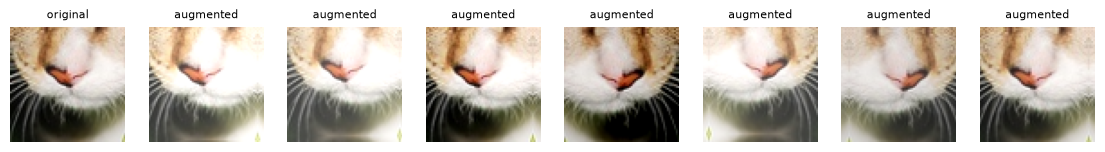

In [ ]:
# Takes a batch of float images, randomly flips 50% of them horizontally, and applies random spatial shifts
def augment(x, max_shift=4):
    """x: float batch in [0,1], shape (B,3,H,W). Every image gets its own random changes."""
    B, C, H, W = x.shape
    flip = torch.rand(B) < 0.5                                   # Horizontal flip
    x = torch.where(flip[:, None, None, None], x.flip(3), x)

    p = max_shift                                                # Random shift
    xp = F.pad(x, (p, p, p, p), mode="reflect")
    oy = torch.randint(0, 2 * p + 1, (B,)); ox = torch.randint(0, 2 * p + 1, (B,))
    rows = oy[:, None] + torch.arange(H)
    cols = ox[:, None] + torch.arange(W)
    x = xp[torch.arange(B)[:, None, None], :, rows[:, :, None], cols[:, None, :]].permute(0, 3, 1, 2)

# Randomly tweaks the brightness and contrast of each image relative to its own mean pixel value
    bright = (torch.rand(B, 1, 1, 1) - 0.5) * 0.4 
    contrast = 1 + (torch.rand(B, 1, 1, 1) - 0.5) * 0.4
    m = x.mean(dim=(1, 2, 3), keepdim=True)
    return ((x - m) * contrast + m + bright).clamp(0, 1)

def prepare(xb_uint8, train, stats, use_aug=True): # Converts raw uint8 image batches into floating-point tensors
    x = xb_uint8.float() / 255
    if train and use_aug: # Conditionally applies data augmentation if training
        x = augment(x)
    mean, std = STATS[stats] # Standardizes the channels
    return ((x - mean[None, :, None, None]) / std[None, :, None, None]).contiguous()

# Grabs a single training image, displays the original in the first plot column, and passes it 
# through the augment function 7 separate times to display different randomized variations side-by-side
fig, axes = plt.subplots(1, 8, figsize=(14, 2))
base = X_tr[:1]
axes[0].imshow(base[0].permute(1, 2, 0).numpy()); axes[0].set_title("original", fontsize=8)
for a in axes[1:]:
    a.imshow(augment(base.float() / 255)[0].permute(1, 2, 0).numpy()); a.set_title("augmented", fontsize=8)
for a in axes:
    a.axis("off")
plt.show()

In [ ]:
# Initializes a PyTorch random number generator
g = torch.Generator(); g.manual_seed(SEED)
train_loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=BATCH_SIZE, shuffle=True, generator=g)
# Wraps training tensors into a TensorDataset, and creates a DataLoader that shuffles the data at every epoch using that generator

# Pulls the first batch of images and labels from the data loader
xb, yb = next(iter(train_loader))
xt = prepare(xb, True, "train") # Passes the raw uint8 images through the prepare pipeline
# Prints out the tensor shapes and data types before and after processing
print("raw batch:", tuple(xb.shape), xb.dtype, "-> prepared:", tuple(xt.shape), xt.dtype)
print("after normalising, mean/std:", round(xt.mean().item(), 3), round(xt.std().item(), 3))
print("batches per epoch:", len(train_loader))

raw batch: (128, 3, 64, 64) torch.uint8 -> prepared: (128, 3, 64, 64) torch.float32
after normalising, mean/std: -0.079 1.088
batches per epoch: 398


In [ ]:
# Packs the training indices, validation indices, full label array, and calculated training channel statistics into a single compressed NumPy archive file
np.savez(CACHE_DIR / "split.npz", idx_tr=idx_tr, idx_va=idx_va, y_all=y_all.numpy(),
         mean=TRAIN_MEAN.numpy(), std=TRAIN_STD.numpy())
json.dump(class_to_idx, open(CACHE_DIR / "class_to_idx.json", "w")) # Serializes the Python dictionary into a standard JSON file
df_model[["image_id", "class"]].to_csv(CACHE_DIR / "train_model_labels.csv", index=False) # Exports the deduplicated dataset's image IDs and corresponding classes into a clean CSV file
print("saved:", sorted(p.name for p in CACHE_DIR.iterdir()))

saved: ['class_to_idx.json', 'split.npz', 'test_64_29443.npy', 'train_64_63645.npy', 'train_md5.csv', 'train_model_labels.csv']
